# ViT · 03-0: Vom Modell zu probly

**Leitfrage des Projekts:** Welche Merkmale machen ein Modell unsicher, und ist diese Unsicherheit
Rauschen in den Daten (aleatorisch, **AU**) oder fehlendes Wissen (epistemisch, **EU**)?

Diese Reihe baut einen **Prototyp einer shapiq-Erweiterung**: das Paket `vit_uncertainty` in diesem Ordner.
Es erklärt bei Bildern nicht nur die Vorhersage, sondern auch ihre Unsicherheit. Der Ablauf hat vier Schritte:

| Schritt | Was passiert | Wo im Paket | Notebook |
|---|---|---|---|
| 1. Modell | zwei eingefrorene Vision Transformer (ViT-S/16 und DINOv2-S/14) | `backbones.py` | **03-0** (dieses) |
| 2. Modell → probly | kleine Köpfe, daraus Ensembles und MC Dropout mit probly | `probly_bridge.py` | **03-0** (dieses) |
| 3. shapiq-Explainer | `UncertaintyExplainer` (ein `shapiq.Explainer`) erklärt P, TU, AU und EU | `game.py`, `explainer.py` | 03-1 |
| 4. Erklärung von beidem | Vorhersage und Unsicherheit nebeneinander | `plot.py` | 03-1 |
| 5. ViT Shapley | ein lernender Erklärer liefert alle vier Karten in einem Durchlauf | `amortized.py` | 03-2 |

**Daten:** Oxford-IIIT Pet (37 Hunde- und Katzenrassen) mit **genau Dans Aufteilung** aus seiner VGG16-Reihe
(Branch `dan/oxford-pets-vgg16`). Dadurch sind unsere Zahlen direkt mit seinen vergleichbar.

**Was wir aus der DermaMNIST-Reihe mitnehmen** (`keith_02_dermamnist`, als Patch):
1. Köpfe auf **einem** eingefrorenen Netz sind sich fast immer einig; ihre EU ist fast null.
   Ein Ensemble aus **verschiedenen** Netzen misst viel mehr fehlendes Wissen.
2. Werden Bildteile mit einer Farbe **übermalt**, kippen die Modelle auf eine sichere Klasse. Erklärungen der
   Unsicherheit hingen dort stark von der Füllfarbe ab. Ein ViT kann Bildteile stattdessen **weglassen**.

**Vorab festgelegte Fragen für dieses Notebook** (auch negative Ergebnisse werden berichtet):

| | Frage | Regel für „gestützt“ |
|---|---|---|
| F1 | Zeigt das gemischte Ensemble (ViT + DINOv2) deutlich mehr EU als das Ensemble nur auf dem ViT? | mittlere EU mindestens doppelt so groß |
| F2 | Kommen Köpfe, die auch auf teilweise ausgeblendeten Bildern trainiert wurden, mit solchen Bildern besser zurecht? | mindestens 5 Prozentpunkte mehr Accuracy auf ausgeblendeten Validierungsbildern |

## 0. Setup

Das Paket liegt im selben Ordner wie dieses Notebook. Alle Zwischenergebnisse landen in
`artifacts/keith-vit-uncertainty/` (in `.gitignore`). Ein Cache wird nur benutzt, wenn er exakt zu den
aktuellen Daten und Modellen passt.

In [1]:
from __future__ import annotations

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import roc_auc_score

# Find the folder of this notebook inside the repository and make the package importable.
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "probly").is_dir())
PACKAGE_DIR = REPO_ROOT / "experiments" / "group-d_experiments" / "keith_03_vit_uncertainty"
sys.path.insert(0, str(PACKAGE_DIR))

from vit_uncertainty import FeatureLayout, OxfordPets, build_methods, default_data_root, load_backbones, settings
from vit_uncertainty.features import ARTIFACT_DIR, full_image_features, load, masked_training_features, save
from vit_uncertainty.probly_bridge import HEAD_CONFIG, make_head, train_head, uncertainty
from probly.metrics import expected_calibration_error, log_loss

torch.set_num_threads(max(1, torch.get_num_threads()))
SEED = settings.SEED
print("Pakete:", {name: __import__(name).__version__ for name in ("torch", "timm", "shapiq", "numpy")})

Pakete: {'torch': '2.15.0+cpu', 'timm': '1.0.31', 'shapiq': '1.8.0', 'numpy': '2.5.4'}


## 1. Daten mit Dans Aufteilung

- Offizielle Listen `trainval` (3680 Bilder) und `test` (3669 Bilder).
- Aus `trainval` wird wie bei Dan stratifiziert 80/20 in Training und Validierung geteilt (Seed 0).
- Jedes Bild wird wie bei Dan auf 256 Pixel skaliert und mittig auf **224 × 224** zugeschnitten. Alle Modelle
  sehen also dieselben Pixel wie Dans VGG16.
- Erklär-Kohorte für 03-1: Dans **ein Testbild je Rasse** (37 Bilder), nur nach Label und Seed gezogen.

Training 2944 | Validierung 736 | Test 3669 | Rassen 37
Erklär-Kohorte (erste 5 Bild-IDs): ['Abyssinian_79', 'american_bulldog_208', 'american_pit_bull_terrier_42', 'basset_hound_66', 'beagle_38']


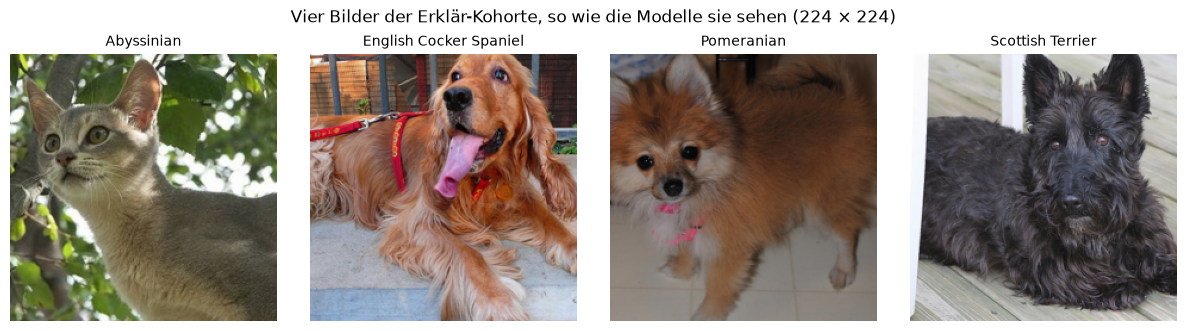

In [2]:
pets = OxfordPets(default_data_root())
train_pos, val_pos = pets.train_val_indices
trainval_ids, trainval_labels, _ = pets.trainval
test_ids, test_labels, test_species = pets.test
print(f"Training {len(train_pos)} | Validierung {len(val_pos)} | Test {len(test_ids)} | Rassen {len(pets.classes)}")
print("Erklär-Kohorte (erste 5 Bild-IDs):", [test_ids[i] for i in pets.cohorts["explanation"][:5]])

examples = [pets.cohorts["explanation"][i] for i in (0, 12, 24, 30)]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), layout="constrained")
for ax, index in zip(axes, examples, strict=True):
    ax.imshow(pets.load_crop(test_ids[index]))
    ax.set_title(pets.classes[test_labels[index]], fontsize=10)
    ax.axis("off")
fig.suptitle("Vier Bilder der Erklär-Kohorte, so wie die Modelle sie sehen (224 × 224)")
plt.show()

## 2. Schritt 1: Zwei eingefrorene Vision Transformer

**Warum Vision Transformer?** Ein ViT zerlegt das Bild in Kacheln (Patches) und verarbeitet jede Kachel als
**Token**. Für Erklärungen ist das ideal: Einen Bildteil kann man **weglassen**, indem man seine Tokens
ausblendet. Man muss ihn nicht mit einer Farbe übermalen. Bei DermaMNIST hatte gerade das Übermalen die
Erklärungen der Unsicherheit stark verändert.

**Warum zwei verschiedene?** Aus DermaMNIST wissen wir: Fehlendes Wissen (EU) sieht ein Ensemble nur, wenn
seine Mitglieder das Bild verschieden „sehen“. Deshalb zwei Transformer, die sehr unterschiedlich gelernt haben:

| Name im Paket | Modell | Wie trainiert | Tokens |
|---|---|---|---|
| `vit` | ViT-S/16 | **überwacht**: Bilder mit Labels (ImageNet-21k, dann ImageNet-1k) | 14 × 14 Kacheln à 16 px |
| `dinov2` | DINOv2-S/14 | **selbstüberwacht**: 142 Mio. Bilder ohne Labels | 16 × 16 Kacheln à 14 px |

**Warum die kleinen „S“-Varianten?** Für Erklärungen läuft jedes Bild hunderte Male durch beide Netze.
Die kleinen Modelle (je ca. 22 Mio. Parameter) sind etwa dreimal so schnell wie ViT-B und laufen auf einer CPU.
Die Netze bleiben **eingefroren**: Sie werden nie trainiert. Das Ergebnis ist pro Bild das Klassen-Token (CLS),
ein Vektor mit 384 Zahlen je Netz.

In [3]:
backbones = load_backbones()
probe = np.stack([pets.load_crop(test_ids[i]) for i in range(16)])
rows = []
for name, backbone in backbones.items():
    backbone.features(probe[:2])
    start = time.perf_counter()
    backbone.features(probe)
    rows.append(
        {
            "Name": name,
            "Modell": backbone.label,
            "Parameter (Mio.)": round(sum(p.numel() for p in backbone.model.parameters()) / 1e6, 1),
            "Tokens": f"{backbone.grid_size[0]} × {backbone.grid_size[1]}",
            "Merkmale": backbone.feature_dim,
            "ms pro Bild (CPU)": round((time.perf_counter() - start) / len(probe) * 1000),
        }
    )
display(pd.DataFrame(rows).set_index("Name"))

,Modell,Parameter (Mio.),Tokens,Merkmale,ms pro Bild (CPU)
Name,,,,,
vit,ViT-S/16,21.7,14 × 14,384,58
dinov2,DINOv2-S/14,21.6,16 × 16,384,63


### 2.1 Merkmale aller Bilder einmal berechnen

Weil die Netze eingefroren sind, ändern sich ihre Merkmale für ein Bild nie. Wir berechnen sie einmal für alle
7349 Bilder und speichern sie (wie Dan). Für den ViT speichern wir zusätzlich die Patch-Tokens; der lernende
Erklärer in 03-2 liest sie. Erster Lauf: auf 2 CPU-Kernen etwa 15 Minuten, danach Sekunden.

In [4]:
full = {split: full_image_features(pets, backbones, split) for split in ("trainval", "test")}
layout = FeatureLayout.from_backbones(backbones)
X = {split: layout.concat(full[split]["features"]) for split in full}  # (N, 768): ViT block, then DINOv2 block
y = {
    "train": torch.from_numpy(trainval_labels[train_pos]),
    "val": torch.from_numpy(trainval_labels[val_pos]),
    "test": torch.from_numpy(test_labels),
}
Xs = {"train": X["trainval"][train_pos], "val": X["trainval"][val_pos], "test": X["test"]}
print(
    {split: tuple(value.shape) for split, value in Xs.items()}, "| Spalten:", {n: layout.span(n) for n in layout.names}
)

Merkmale 'trainval' aus dem Cache geladen (3680 Bilder).


Merkmale 'test' aus dem Cache geladen (3669 Bilder).
{'train': (2944, 768), 'val': (736, 768), 'test': (3669, 768)} | Spalten: {'vit': (0, 384), 'dinov2': (384, 768)}


### 2.2 Teilweise ausgeblendete Bilder (für die Köpfe und für ViT Shapley)

Später erklären wir das Modell, indem wir Bildteile ausblenden. Ein Kopf, der nur vollständige Bilder kennt,
sieht dann Eingaben, die er nie gesehen hat. Covert et al. (ViT Shapley, 2023) trainieren deshalb ein
**Ersatzmodell** (Surrogat), das auch Bilder mit ausgeblendeten Teilen kennt. Wir machen eine leichte Version davon:

- Jedes Trainingsbild wird in **16 SLIC-Superpixel** zerlegt (wie bei Tom).
- Für jedes Bild ziehen wir **8 zufällige Koalitionen** (Validierung: 4): Welche Superpixel bleiben sichtbar?
  Die Größe folgt dem Shapley-Kern: sehr kleine und sehr große Koalitionen kommen öfter vor.
- Die Tokens der übrigen Superpixel werden ausgeblendet, und beide Netze berechnen die Merkmale.

Dieselben Daten trainieren in 03-2 auch den lernenden Erklärer.

In [5]:
masked = {
    "val": masked_training_features(pets, backbones, val_pos, name="val", per_image=settings.MASKED_PER_IMAGE_VAL),
    "train": masked_training_features(
        pets, backbones, train_pos, name="train", per_image=settings.MASKED_PER_IMAGE_TRAIN
    ),
}
Xm = {split: layout.concat(masked[split]["features"]) for split in masked}
ym = {split: torch.from_numpy(trainval_labels[masked[split]["positions"].numpy()]) for split in masked}
sizes = masked["train"]["coalitions"].sum(1).numpy()
print(
    {split: tuple(value.shape) for split, value in Xm.items()},
    "| sichtbare Superpixel je Koalition (Median, 10.–90. Perzentil):",
    int(np.median(sizes)),
    np.percentile(sizes, [10, 90]).astype(int).tolist(),
)

Maskierte Merkmale 'val' aus dem Cache geladen (2944 Zeilen).


Maskierte Merkmale 'train' aus dem Cache geladen (23552 Zeilen).
{'val': (2944, 768), 'train': (23552, 768)} | sichtbare Superpixel je Koalition (Median, 10.–90. Perzentil): 8 [1, 15]


## 3. Schritt 2: Modell → probly

### 3.1 Köpfe trainieren

- Jeder Kopf ist **Dropout(0,5) → Linear(384, 37)** auf den Merkmalen eines Netzes, mit **Dans Einstellungen**
  (AdamW, Lernrate 1e-3, Weight Decay 1e-4, Batch 64, Early Stopping nach dem Validierungsverlust).
- Je Netz **6 Köpfe** (Seeds 0 bis 5) in zwei Varianten:
  - **normal**: nur auf vollständigen Bildern trainiert (wie Dan),
  - **maskiert**: auf vollständigen **und** teilweise ausgeblendeten Bildern trainiert (leichtes Surrogat).
- Insgesamt 24 Köpfe; auf der CPU dauert das wenige Minuten. Das Ergebnis wird gespeichert.

In [6]:
HEADS_PATH = ARTIFACT_DIR / "heads.pt"
heads_manifest = {
    "config": HEAD_CONFIG,
    "seeds": settings.N_MEMBERS,
    "layout": [layout.names, layout.dims],
    "masked": [masked[s]["manifest"] for s in ("train", "val")],
}
cached = load(HEADS_PATH)
if cached is not None and cached["manifest"] == heads_manifest:
    heads = cached["heads"]
    print("Passende Köpfe aus heads.pt geladen.")
else:
    heads, start = {"normal": {}, "maskiert": {}}, time.perf_counter()
    for variant in heads:
        for name in layout.names:
            a, b = layout.span(name)
            if variant == "normal":
                train = (Xs["train"][:, a:b], y["train"])
                val = (Xs["val"][:, a:b], y["val"])
            else:  # full images plus partially hidden images, the same labels
                train = (torch.cat([Xs["train"][:, a:b], Xm["train"][:, a:b]]), torch.cat([y["train"], ym["train"]]))
                val = (torch.cat([Xs["val"][:, a:b], Xm["val"][:, a:b]]), torch.cat([y["val"], ym["val"]]))
            heads[variant][name] = []
            for seed in range(settings.N_MEMBERS):
                head = make_head(b - a, len(pets.classes), dropout=HEAD_CONFIG["dropout"], seed=seed)
                heads[variant][name].append(train_head(head, train, val, seed=seed)["state_dict"])
    save(HEADS_PATH, {"manifest": heads_manifest, "heads": heads})
    print(f"24 Köpfe trainiert in {time.perf_counter() - start:.0f} s.")

Passende Köpfe aus heads.pt geladen.


### 3.2 Die probly-Methoden

Aus den Köpfen baut `build_methods` je Variante drei probly-Methoden. Alle Ensembles haben **6 Mitglieder**,
denn die EU hängt auch von der Zahl der Mitglieder ab.

| Methode | Mitglieder | Variante aus deiner Frage |
|---|---|---|
| `Ensemble ViT` | 6 Köpfe auf dem ViT | a |
| `MC Dropout ViT` | Kopf 0 auf dem ViT, Dropout bleibt beim Vorhersagen aktiv, 50 Durchläufe | a |
| `Gemischt` | 3 Köpfe auf dem ViT + 3 Köpfe auf DINOv2 | b |

**Technischer Punkt:** `probly.method.ensemble` kopiert normalerweise **ein** Grundmodell. Unsere Mitglieder
sitzen auf verschiedenen Netzen. Jedes Mitglied bekommt deshalb denselben Eingabevektor (768 Zahlen) und schneidet
mit `FeatureSlice` seinen Teil heraus. probly baut den Ensemble-Container; wir setzen die trainierten Köpfe ein.
Danach läuft alles über die normale probly-Pipeline `representer` → `quantify`.

Gerechnet wird in 64-Bit (sonst weicht TU = AU + EU um etwa 1e-7 ab). MC Dropout wird Bild für Bild mit demselben
Seed ausgewertet, damit jedes Bild dieselben 50 Dropout-Masken sieht.

In [7]:
methods = {variant: build_methods(layout, heads[variant], n_members=settings.N_MEMBERS) for variant in heads}
print(methods["normal"]["Gemischt"])

# Check probly against a hand computation for the mixed ensemble (TU = H(mean p), AU = mean H(p_m)).
probe_x = Xs["test"][:100].double()
members = methods["normal"]["Gemischt"]
with torch.no_grad():
    p = torch.stack([m(probe_x).softmax(-1) for m in members])
entropy = lambda q: -(q * q.clamp_min(1e-300).log()).sum(-1)  # noqa: E731
scores = uncertainty(members, probe_x)
np.testing.assert_allclose(scores["TU"], entropy(p.mean(0)).numpy(), atol=1e-10)
np.testing.assert_allclose(scores["EU"], (entropy(p.mean(0)) - entropy(p).mean(0)).numpy(), atol=1e-10)
np.testing.assert_allclose(scores["TU"], scores["AU"] + scores["EU"], atol=1e-12)
print("probly stimmt mit der Handrechnung überein; TU = AU + EU gilt für jedes Bild.")

ModuleList(
  (0-2): 3 x Sequential(
    (0): FeatureSlice(vit, columns 0:384)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=384, out_features=37, bias=True)
  )
  (3-5): 3 x Sequential(
    (0): FeatureSlice(dinov2, columns 384:768)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=384, out_features=37, bias=True)
  )
)


probly stimmt mit der Handrechnung überein; TU = AU + EU gilt für jedes Bild.


## 4. Wie gut sind die Methoden, und wie unsicher?

Zuerst auf den **vollständigen Testbildern** (3669). Zum Vergleich Dans VGG16-Werte aus seiner Reihe
(`dan_02-0`/`dan_02-1`): Accuracy 90,1 %, NLL 0,285, mittlere EU seines Ensembles aus drei Köpfen 0,0071 nats.

In [8]:
test_scores = {
    (variant, name): uncertainty(predictor, Xs["test"], num_samples=settings.MC_SAMPLES)
    for variant in methods
    for name, predictor in methods[variant].items()
}
rows = []
for (variant, name), s in test_scores.items():
    probabilities = torch.from_numpy(s["probabilities"])
    correct = (probabilities.argmax(1) == y["test"]).numpy()
    rows.append(
        {
            "Köpfe": variant,
            "Methode": name,
            "Accuracy": correct.mean(),
            "NLL": float(log_loss(probabilities, y["test"])),
            "ECE (15 Bins)": float(expected_calibration_error(probabilities, y["test"], num_bins=15)),
            "TU": s["TU"].mean(),
            "AU": s["AU"].mean(),
            "EU": s["EU"].mean(),
            "Error-AUROC EU": roc_auc_score(~correct, s["EU"]),
            "Error-AUROC 1 − max(p)": roc_auc_score(~correct, 1 - s["probabilities"].max(1)),
        }
    )
rows.append(
    {
        "Köpfe": "Dan",
        "Methode": "VGG16 Ensemble (3 Köpfe)",
        "Accuracy": 0.8986,
        "NLL": 0.2825,
        "ECE (15 Bins)": 0.0187,
        "EU": 0.0071,
        "Error-AUROC EU": 0.889,
        "Error-AUROC 1 − max(p)": 0.925,
    }
)
quality = pd.DataFrame(rows).set_index(["Köpfe", "Methode"])
display(
    quality.style.format(
        {
            "Accuracy": "{:.1%}",
            "NLL": "{:.3f}",
            "ECE (15 Bins)": "{:.3f}",
            "TU": "{:.3f}",
            "AU": "{:.3f}",
            "EU": "{:.4f}",
            "Error-AUROC EU": "{:.3f}",
            "Error-AUROC 1 − max(p)": "{:.3f}",
        },
        na_rep="—",
    )
)

### 4.1 F1: Misst das gemischte Ensemble mehr fehlendes Wissen?

Regel (vorab): **gestützt**, wenn die mittlere EU von `Gemischt` mindestens doppelt so groß ist wie die von
`Ensemble ViT` (normale Köpfe, vollständige Testbilder).

Weil beide Gruppen gleich groß sind (3 + 3), lässt sich die EU des gemischten Ensembles **exakt** aufteilen in
„Uneinigkeit **zwischen** den Netzen“ und „Uneinigkeit der Köpfe **innerhalb** eines Netzes“:
EU = [H(p̄) − ½(H(p̄_ViT) + H(p̄_DINO))] + ½(EU_ViT-Gruppe + EU_DINO-Gruppe).

- Mittlere EU: Gemischt **0.0368**, Ensemble ViT **0.0147**, MC Dropout ViT 0.1019 nats (Dan, VGG16-Ensemble: 0,0071).
- Verhältnis Gemischt / Ensemble ViT: **2.5×**. Anteil der EU, der **zwischen** den Netzen entsteht: **73%**.
- **F1 nach der Regel: gestützt.**

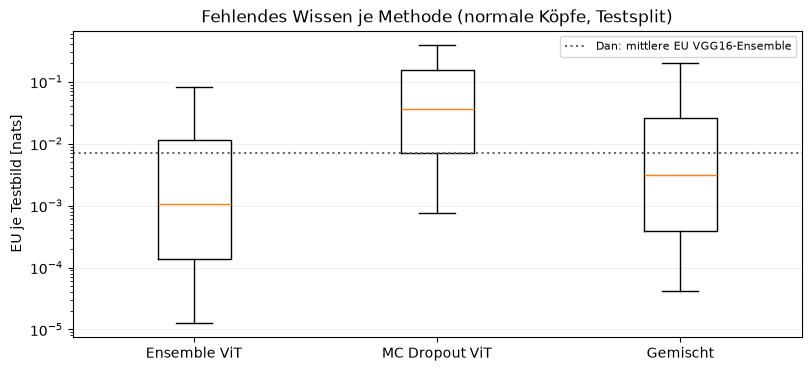

In [9]:
eu = {name: test_scores[("normal", name)]["EU"] for name in methods["normal"]}
ratio = eu["Gemischt"].mean() / eu["Ensemble ViT"].mean()
with torch.no_grad():
    p = torch.stack([m(Xs["test"].double()).softmax(-1) for m in methods["normal"]["Gemischt"]])
p_vit, p_dino = p[:3], p[3:]
group_eu = lambda q: entropy(q.mean(0)) - entropy(q).mean(0)  # noqa: E731
within = 0.5 * (group_eu(p_vit) + group_eu(p_dino))
between = entropy(p.mean(0)) - 0.5 * (entropy(p_vit.mean(0)) + entropy(p_dino.mean(0)))
np.testing.assert_allclose((within + between).numpy(), eu["Gemischt"], atol=1e-10)
F1 = ratio >= 2
display(
    Markdown(
        f"- Mittlere EU: Gemischt **{eu['Gemischt'].mean():.4f}**, Ensemble ViT **{eu['Ensemble ViT'].mean():.4f}**, "
        f"MC Dropout ViT {eu['MC Dropout ViT'].mean():.4f} nats (Dan, VGG16-Ensemble: 0,0071).\n"
        f"- Verhältnis Gemischt / Ensemble ViT: **{ratio:.1f}×**. "
        f"Anteil der EU, der **zwischen** den Netzen entsteht: **{between.sum() / (within + between).sum():.0%}**.\n"
        f"- **F1 nach der Regel: {'gestützt' if F1 else 'nicht gestützt'}.**"
    )
)

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
names = list(eu)
ax.boxplot([np.clip(eu[n], 1e-7, None) for n in names], whis=(5, 95), showfliers=False)
ax.set_xticks(range(1, len(names) + 1), names)
ax.set_yscale("log")
ax.axhline(0.0071, color="0.4", linestyle=":", label="Dan: mittlere EU VGG16-Ensemble")
ax.set(ylabel="EU je Testbild [nats]", title="Fehlendes Wissen je Methode (normale Köpfe, Testsplit)")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.2)
plt.show()

### 4.2 F2: Was passiert mit teilweise ausgeblendeten Bildern?

Jetzt auf den **ausgeblendeten Validierungsbildern** (736 Bilder × 4 Koalitionen). Regel (vorab): **gestützt**,
wenn die maskiert trainierten Köpfe dort mindestens 5 Prozentpunkte mehr Accuracy haben als die normalen.

Dazu der Extremfall **v(∅)**: Alle Superpixel sind ausgeblendet, nur das CLS-Token bleibt. Dann bekommt jedes
Bild exakt dieselbe Eingabe; das Modell weiß nichts über das Bild. Eine ehrliche Antwort wäre „keine Ahnung“,
also eine fast gleichmäßige Verteilung über 37 Rassen: TU nahe ln 37 ≈ 3,61 nats. Dieser Wert ist der
**Ausgangspunkt jeder Erklärung** in 03-1.

In [10]:
empty_x = layout.concat(
    {name: b.features(probe[:1], np.zeros((1, b.n_patches), dtype=bool)) for name, b in backbones.items()}
)
rows = []
for variant in methods:
    for name, predictor in methods[variant].items():
        s = uncertainty(predictor, Xm["val"], num_samples=settings.MC_SAMPLES)
        e = uncertainty(predictor, empty_x, num_samples=settings.MC_SAMPLES)
        rows.append(
            {
                "Köpfe": variant,
                "Methode": name,
                "Accuracy ausgeblendet": (s["probabilities"].argmax(1) == ym["val"].numpy()).mean(),
                "NLL ausgeblendet": float(log_loss(torch.from_numpy(s["probabilities"]), ym["val"])),
                "EU ausgeblendet": s["EU"].mean(),
                "v(∅): größte Wahrscheinlichkeit": e["probabilities"].max(),
                "v(∅): Klasse": pets.classes[int(e["probabilities"].argmax())],
                "v(∅): TU": e["TU"][0],
                "v(∅): EU": e["EU"][0],
            }
        )
partial = pd.DataFrame(rows).set_index(["Köpfe", "Methode"])
display(
    partial.style.format(
        {
            "Accuracy ausgeblendet": "{:.1%}",
            "NLL ausgeblendet": "{:.3f}",
            "EU ausgeblendet": "{:.4f}",
            "v(∅): größte Wahrscheinlichkeit": "{:.1%}",
            "v(∅): TU": "{:.3f}",
            "v(∅): EU": "{:.4f}",
        }
    )
)
gain = (
    partial.loc[("maskiert", "Gemischt"), "Accuracy ausgeblendet"]
    - partial.loc[("normal", "Gemischt"), "Accuracy ausgeblendet"]
)
F2 = gain >= 0.05
display(
    Markdown(
        f"- Gemischt, maskiert gegen normal: **{gain * 100:+.1f} Prozentpunkte** Accuracy auf "
        f"ausgeblendeten Bildern.\n- **F2 nach der Regel: {'gestützt' if F2 else 'nicht gestützt'}.**"
    )
)

- Gemischt, maskiert gegen normal: **+4.1 Prozentpunkte** Accuracy auf ausgeblendeten Bildern.
- **F2 nach der Regel: nicht gestützt.**

## 5. Ergebnis und was wir daraus lernen

In [11]:
verdicts = pd.DataFrame(
    {
        "Frage": ["F1 gemischt ≥ 2× EU", "F2 maskiert trainiert hilft bei ausgeblendeten Bildern"],
        "Kennzahl": [f"{ratio:.1f}×", f"{gain * 100:+.1f} Prozentpunkte"],
        "Ergebnis": ["gestützt" if F1 else "nicht gestützt", "gestützt" if F2 else "nicht gestützt"],
    }
).set_index("Frage")
display(verdicts)

,Kennzahl,Ergebnis
Frage,,
F1 gemischt ≥ 2× EU,2.5×,gestützt
F2 maskiert trainiert hilft bei ausgeblendeten Bildern,+4.1 Prozentpunkte,nicht gestützt


**Was die Ergebnisse in einfachen Worten sagen** (Zahlen aus unserem Lauf, siehe Tabellen oben)

1. **Die Transformer sind besser als VGG16.** Der ViT allein erreicht 93,2 % Accuracy, das gemischte Ensemble
   95,0 % (Dan mit VGG16: 89,9 bis 90,1 %). Auch die NLL ist deutlich kleiner (0,16 gegenüber 0,28).
2. **F1 ist gestützt.** Das gemischte Ensemble hat im Mittel 0,037 nats EU, das ViT-Ensemble 0,015
   (2,5-mal so viel). **73 % der EU entstehen zwischen den beiden Netzen.** Das bestätigt die Lehre aus
   DermaMNIST auf einem zweiten Datensatz: Fehlendes Wissen sieht man vor allem dort, wo Modelle das Bild
   verschieden sehen.
3. **MC Dropout zeigt die meiste EU (0,10), ist aber am schlechtesten kalibriert** (ECE 0,033). Die Höhe seiner
   EU hängt direkt an der Dropout-Rate 0,5; sie ist kein Beweis für mehr echtes fehlendes Wissen.
4. **EU ist weiterhin nicht der beste Fehlerdetektor.** In allen sechs Varianten erkennt `1 − max(p)` Fehler
   besser (Error-AUROC 0,91 bis 0,93) als die EU (0,87 bis 0,91). Das passt zu Dan und zu DermaMNIST: EU heißt „die Mitglieder sind uneinig“, nicht
   „die Vorhersage ist falsch“.
5. **F2 ist nach der Regel nicht gestützt** (+4,1 statt mindestens 5 Prozentpunkte). Das maskierte Training hilft
   trotzdem sichtbar: Die NLL auf ausgeblendeten Bildern sinkt von 0,96 auf 0,77, und **die EU auf
   ausgeblendeten Bildern sinkt deutlich** (ViT-Ensemble von 0,084 auf 0,042, gemischt von 0,186 auf 0,130).
   Genau das sollte fehlendes Wissen tun: Kennt das Modell solche Bilder, weiß es mehr über sie. Der Preis ist
   etwas weniger Accuracy auf vollständigen Bildern (94,4 statt 95,0 %).
6. **Das komplett ausgeblendete Bild ist ein ehrliches „keine Ahnung“.** Mit Token-Weglassen liegt die TU von
   v(∅) bei 3,45 bis 3,54 nats, nahe am Maximum ln 37 ≈ 3,61; die größte Wahrscheinlichkeit liegt bei 5 bis 9 %.
   Bei DermaMNIST war das übermalte leere Bild dagegen ein **sicheres** „Nävus“ (TU ≈ 0,05). Der Ausgangspunkt
   jeder Erklärung ist hier also „das Modell weiß nichts“, nicht „das Modell ist sich fälschlich sicher“.

**Was das für die Leitfrage bedeutet**

- Ob man fehlendes Wissen sieht, hängt an der Wahl der Ensemble-Mitglieder (F1), und wie viel fehlendes Wissen
  ein Modell über ausgeblendete Bilder hat, hängt daran, ob es solche Bilder kennt (F2).
- Weil v(∅) fast maximale Unsicherheit hat, werden die Beiträge zu TU in 03-1 überwiegend **negativ** sein:
  Ein Bildteil zu sehen **senkt** die Unsicherheit. Bei DermaMNIST war es umgekehrt. Die Erklärung erzählt
  hier also die natürliche Geschichte: „Dieser Bildteil liefert Wissen.“

**Was das für unser Paket bedeutet**

- Standard des Explainers ist **Token-Weglassen**; es vermeidet den Zusammenbruch auf eine sichere Klasse.
- Hauptkonfiguration für 03-1 und 03-2 ist **`Gemischt` mit maskierten Köpfen**: Sie hat die meiste EU unter
  den Ensembles und kennt die teilweise ausgeblendeten Bilder, die eine Erklärung auswertet. Dass F2 die Schwelle
  knapp verfehlt, berichten wir trotzdem.
- Für probly ist ein Ensemble aus verschiedenen Netzen der wichtigste Baustein; `probly.method.ensemble`
  unterstützt das nicht direkt (wir brauchen `FeatureSlice`). Das ist ein Punkt für die Betreuer.

**Grenzen**

- Ein Satz Seeds; die Backbones bleiben eingefroren; MC Dropout nur mit einer Dropout-Rate (0,5).
- Dans Zahlen stammen aus seinen Notebooks (3 Köpfe, VGG16); unsere Ensembles haben 6 Mitglieder.